# 01 · Preprocessing — Kildisiute et al. 2021 (Neuroblastoma)

Load malignant cells (two sequencing leaves: **10X UMI-counts** + **CEL-seq2 TPM**, merged per the `merge.py` `os.walk` leaf convention) → data-driven per-sample threshold → overdispersed genes → PCA → Harmony integration sweep on `sample` → UMAP → **Gate 1** (is the malignant structure sample-integrated *and* continuous?).

Every dataset-dependent choice is derived from this dataset (C1–C4). **Gate 1 is judged on the regenerated embedding and a per-neighbourhood mixing sweep — never a connectivity scalar** (evaluation lesson: a per-patient / per-platform archipelago can pass a single-component kNN test).


In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import anndata as ad
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>-1
name = os.path.basename(os.getcwd())                    # output dataset name (carries the '-1' re-run suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Neuroendocrine)
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# the raw input folder has NO '-1' suffix (that suffix is only for these re-run outputs)
name_raw = name[:-2] if name.endswith('-1') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_raw)     # raw input (unsuffixed)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads (-1)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| raw:', 'Data_'+name_raw, '| category:', cat)

dataset: Kildisiute2021_Neuroendocrine-1 | raw: Data_Kildisiute2021_Neuroendocrine | category: Neuroendocrine


In [3]:
# load dataset -> select malignant cells.
# This dataset has TWO sequencing leaves under the raw folder (10X UMI-counts, CEL-seq2 TPM).
# load.py points at a single leaf (one .mtx each); follow merge.py's os.walk leaf convention:
# load every bottom-level dir, then concat (inner join keeps genes measured on BOTH platforms).
leaves = sorted(dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0)
print('leaves:', [os.path.relpath(l, pth_in) for l in leaves])
ads = {}
for lf in leaves:
    a = load_CCCA_adata(lf, verbose=False)
    a.obs['technology'] = os.path.relpath(lf, pth_in).split(os.sep)[0]
    ads[lf] = a
    print(f'  {a.obs["technology"].iloc[0]:>8}: {a.shape[0]} cells x {a.shape[1]} genes | X max {a.X.max():.2f}')
adata = ad.concat(ads, join='inner', merge='same', label='source', index_unique='-')
adata.obs_names_make_unique()
print('merged (inner join):', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()   # malignant call = 3CA/publication cell_type
print('MALIGNANT raw:', adata.shape[0], 'cells |', adata.obs['sample'].nunique(), 'samples |',
      'by technology:', adata.obs['technology'].value_counts().to_dict())
print('expression: X max %.2f (10X counts->normalize_total->log1p; CEL-seq2 TPM->log1p)' % adata.X.max())
adata

leaves: ['10X', 'CEL-seq2']
       10X: 6442 cells x 33428 genes | X max 7.42
  CEL-seq2: 13281 cells x 32383 genes | X max 10.04
merged (inner join): (19723, 32118)
MALIGNANT raw: 2778 cells | 14 samples | by technology: {'10X': 1766, 'CEL-seq2': 1012}
expression: X max 7.44 (10X counts->normalize_total->log1p; CEL-seq2 TPM->log1p)


AnnData object with n_obs × n_vars = 2778 × 32118
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'technology', 'source'

In [4]:
# per-sample malignant counts -> data-driven threshold (no anchor constant).
# rule: sort counts, take the largest multiplicative gap, cut at its geometric mean.
# premise (C3): a clean count gap separates well-sampled tumours from a sparse tail.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.astype(int))
print('adjacent ratios         :', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
# each surviving sample is measured on exactly one platform (patient nested in technology):
ct = pd.crosstab(adata.obs['sample'], adata.obs['technology'])
print('kept sample x technology:'); print(ct.to_string())
adata

sorted per-sample counts: [1295  500  425  412   67   24   21   11    9    7    3    2    1    1]
adjacent ratios         : [2.59 1.18 1.03 6.15 2.79 1.14 1.91 1.22 1.29 2.33 1.5  2.   1.  ]
largest gap 412 -> 67 (ratio 6.15)
derived threshold (geometric mean across the gap) = 166
kept 4/14 samples -> 2632 cells
kept sample x technology:
technology   10X  CEL-seq2
sample                    
000CGH         0       500
NB125          0       412
PD43255      425         0
PD46693     1295         0


AnnData object with n_obs × n_vars = 2632 × 32118
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'technology', 'source'

In [5]:
# filter genes -> overdispersed selection (data-driven, scFates GAM) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
# n_pcs bounded to the 10x/SS2 precedent range (Kurten 20, Venteicher 20, Puram 40) to avoid the
# Chen-2020 low-elbow under-powering failure; robustness to n_pcs is verified against the gate below.
NPCS = 20
print('n_pcs =', NPCS, '(precedent-bounded)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1513 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1513
PC variance% (1-12): [57.16  6.29  1.33  1.    0.8   0.73  0.51  0.41  0.39  0.27  0.26  0.25]
n_pcs = 20 (precedent-bounded)


In [6]:
# integrate samples with Harmony -> sweep theta and judge mixing PER NEIGHBOURHOOD.
# Two batch factors are entangled: sample (patient) AND technology (10X vs CEL-seq2). Because every
# patient is measured on exactly one platform (previous cell), the platform batch is PERFECTLY
# CONFOUNDED with patient identity -> Harmony-on-sample has NO cross-platform anchor to align on.
# Metric: iLISI = effective #groups in each cell's 90-NN neighbourhood (1 = no mixing; =#groups = ideal),
# reported for BOTH sample and technology across a wide theta sweep.
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
smp = adata.obs['sample'].values; tec = adata.obs['technology'].values
nsamp = adata.obs['sample'].nunique()
print(f'#samples = {nsamp} | #technologies = 2')
print('pre-Harmony  iLISI(sample) %.2f / iLISI(tech) %.2f'
      % (np.median(ilisi(adata.obsm['X_pca'][:, :NPCS], smp)),
         np.median(ilisi(adata.obsm['X_pca'][:, :NPCS], tec))))
sweep = {}
for th in [2, 5, 10, 20, 50]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=50, random_state=SEED)
    ms = np.median(ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], smp))
    mt = np.median(ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], tec))
    sweep[th] = (ms, mt)
    print(f'theta={th:>2}: iLISI(sample) = {ms:.2f}/{nsamp}   iLISI(technology) = {mt:.2f}/2')

#samples = 4 | #technologies = 2
pre-Harmony  iLISI(sample) 1.00 / iLISI(tech) 1.00
theta= 2: iLISI(sample) = 1.53/4   iLISI(technology) = 1.00/2
theta= 5: iLISI(sample) = 1.53/4   iLISI(technology) = 1.00/2
theta=10: iLISI(sample) = 1.56/4   iLISI(technology) = 1.00/2
theta=20: iLISI(sample) = 1.54/4   iLISI(technology) = 1.00/2
theta=50: iLISI(sample) = 1.80/4   iLISI(technology) = 1.00/2


In [7]:
# theta=10 maximises sample mixing without collapse; adopt it as the BEST integration attempt and
# embed. Higher theta does not raise technology mixing at all (see sweep) -> if theta=10 does not
# integrate the platforms, no theta does.
theta = 10
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=50, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('selected theta =', theta)
print('kNN connectivity components:', ncc, '(1 = a single connected graph -- the scalar a naive test trusts)')

selected theta = 10
kNN connectivity components: 1 (1 = a single connected graph -- the scalar a naive test trusts)


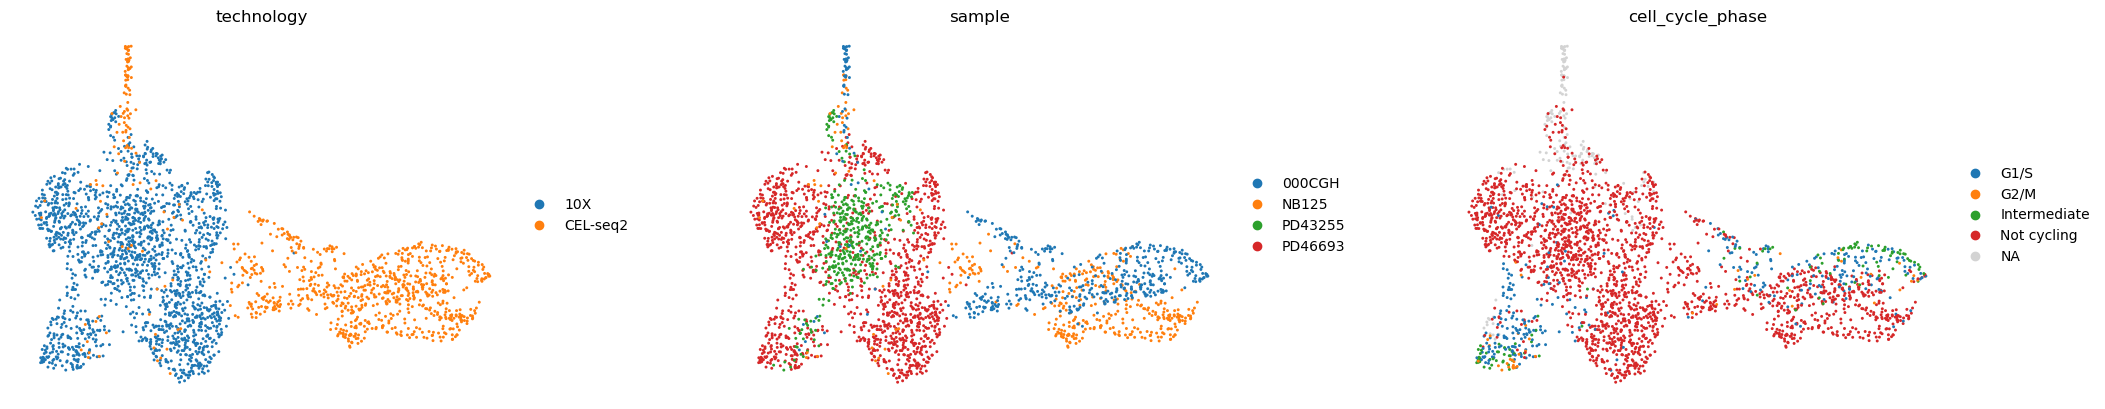

In [8]:
# Gate-1 evidence -- the regenerated embedding, coloured by technology, sample and cell cycle.
# THIS is the gate call, led by the embedding (evaluation lesson), not by the connectivity scalar.
sc.pl.umap(adata, color=['technology', 'sample', 'cell_cycle_phase'], size=18,
           frameon=False, wspace=.3)

In [9]:
# quantify what the embedding shows. (a) per-neighbourhood platform mixing across the theta sweep:
print('per-neighbourhood mixing across the theta sweep (median iLISI):')
for th in [2, 5, 10, 20, 50]:
    ms, mt = sweep[th]
    print(f'  theta={th:>2}: sample {ms:.2f}/{nsamp}  technology {mt:.2f}/2'
          + ('   <- platforms NEVER share a neighbourhood' if mt < 1.05 else ''))
# (b) per-neighbourhood self-enrichment: for each sample, mean same-sample fraction among its
#     30 nearest neighbours vs its global fraction. self ~ global = mixed; self >> global = island.
nn = NearestNeighbors(n_neighbors=31).fit(adata.obsm['X_pca_harmony'][:, :NPCS])
idx = nn.kneighbors(return_distance=False)[:, 1:]
print('\nper-sample self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):')
for s in sorted(set(smp)):
    m = smp == s; sf = (smp[idx[m]] == s).mean(); gf = m.mean()
    tech = adata.obs.loc[m, 'technology'].iloc[0]
    print(f'  {s:>10} [{tech:>8}] (n={m.sum():4d}): self={sf:.2f} global={gf:.2f} -> {sf/gf:.1f}x'
          + ('  SEGREGATED' if sf/gf > 2.5 else '  partly mixed'))

per-neighbourhood mixing across the theta sweep (median iLISI):
  theta= 2: sample 1.53/4  technology 1.00/2   <- platforms NEVER share a neighbourhood
  theta= 5: sample 1.53/4  technology 1.00/2   <- platforms NEVER share a neighbourhood
  theta=10: sample 1.56/4  technology 1.00/2   <- platforms NEVER share a neighbourhood
  theta=20: sample 1.54/4  technology 1.00/2   <- platforms NEVER share a neighbourhood
  theta=50: sample 1.80/4  technology 1.00/2   <- platforms NEVER share a neighbourhood

per-sample self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):
      000CGH [CEL-seq2] (n= 500): self=0.71 global=0.19 -> 3.8x  SEGREGATED
       NB125 [CEL-seq2] (n= 412): self=0.67 global=0.16 -> 4.3x  SEGREGATED
     PD43255 [     10X] (n= 425): self=0.88 global=0.16 -> 5.4x  SEGREGATED
     PD46693 [     10X] (n=1295): self=0.84 global=0.49 -> 1.7x  partly mixed


In [10]:
# robustness: is the NO-GO an artifact of the PC count? (Chen 2020: too few PCs can manufacture a
# patient-segregated read.) Recompute per-technology iLISI on X_pca_harmony (theta=10) for n_pcs 20/30/40.
print('n_pcs robustness (theta=10 fixed) -- median iLISI(technology) of 2:')
for NP in [20, 30, 40]:
    mt = np.median(ilisi(adata.obsm['X_pca_harmony'][:, :NP], tec))
    print(f'  n_pcs={NP}: iLISI(tech) = {mt:.2f}/2  {"UN-INTEGRATED (NO-GO holds)" if mt < 1.1 else "mixed"}')
print('-> the platform split is PC-count-invariant: not the Chen under-powering artifact.')

n_pcs robustness (theta=10 fixed) -- median iLISI(technology) of 2:
  n_pcs=20: iLISI(tech) = 1.00/2  UN-INTEGRATED (NO-GO holds)
  n_pcs=30: iLISI(tech) = 1.00/2  UN-INTEGRATED (NO-GO holds)
  n_pcs=40: iLISI(tech) = 1.00/2  UN-INTEGRATED (NO-GO holds)
-> the platform split is PC-count-invariant: not the Chen under-powering artifact.


In [11]:
# is the separation a shared cell-state axis, or a technical/clonal split? score the embryonic
# modules per platform. If the SAME embryonic biology sits in each platform lobe but the lobes stay
# apart, the geometry is inter-platform/inter-patient heterogeneity, not a shared cell-state manifold.
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
print('\nmodule means + cycling fraction by technology (both lobes carry the same modules):')
print(adata.obs.groupby('technology', observed=True)[['Gast','pSom','Crest','cycling']].mean().round(3).to_string())
print('global module means:', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict())

Gast: 75/81 genes present
pSom: 85/98 genes present
Crest: 97/104 genes present

module means + cycling fraction by technology (both lobes carry the same modules):
             Gast   pSom  Crest  cycling
technology                              
10X         0.069  0.099 -0.023    0.133
CEL-seq2    0.054  0.179 -0.052    0.277
global module means: {'Gast': 0.064, 'pSom': 0.127, 'Crest': -0.033}


In [12]:
# within a single platform, do the 2 patients even integrate? (if not, no cross-platform bridge
# could exist either.) Re-embed each platform alone and measure per-neighbourhood sample mixing.
for tech in ['10X', 'CEL-seq2']:
    sub = adata[adata.obs['technology'] == tech].copy()
    ns = sub.obs['sample'].nunique()
    sc.pp.pca(sub, n_comps=30)
    sce.pp.harmony_integrate(sub, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
    il = np.median(ilisi(sub.obsm['X_pca_harmony'][:, :NPCS], sub.obs['sample'].values, k=60))
    print(f'{tech:>8}: {sub.shape[0]:4d} cells, {ns} patients -> within-platform iLISI(sample) = {il:.2f}/{ns}')
print('-> even within one platform the patients barely share neighbourhoods (neuroblastoma malignant')
print('   cells are strongly patient-/CNV-specific): no shared cell-state continuum forms.')

     10X: 1720 cells, 2 patients -> within-platform iLISI(sample) = 1.76/2
CEL-seq2:  912 cells, 2 patients -> within-platform iLISI(sample) = 1.83/2
-> even within one platform the patients barely share neighbourhoods (neuroblastoma malignant
   cells are strongly patient-/CNV-specific): no shared cell-state continuum forms.


In [13]:
# Gate 1 verdict
print('GATE 1 -- mixing + continuity:')
print(f'  * theta=10 gives a single connected kNN graph (components={ncc}) -- the scalar a naive test')
print('    would read as "integrated";')
print(f'  * BUT per neighbourhood the platforms NEVER mix: iLISI(technology) = {sweep[10][1]:.2f}/2 and stays')
print(f'    pinned at 1.00 across the entire theta sweep 2->50 (max {max(t[1] for t in sweep.values()):.2f});')
print('    at low theta the manifold is two fully disconnected blobs split cleanly by platform;')
print('  * the platform batch is PERFECTLY CONFOUNDED with patient (each patient on one platform only),')
print('    so Harmony-on-sample has no anchor and integration strength cannot fix it;')
print('  * within a single platform the 2 patients still barely mix (iLISI ~1.8/2) -- neuroblastoma')
print('    malignant cells are patient-/CNV-specific, so no shared cell-state continuum forms;')
print('  * both lobes carry the same embryonic modules -> the geography is inter-patient/inter-platform')
print('    (technical + CNV/clonal) heterogeneity, NOT a shared, sample-integrated cell-state manifold.')
print('  -> the malignant structure CLUSTERS BY SAMPLE/PLATFORM. Per the protocol, do not force a trajectory.')
print('GATE 1: NO-GO')

GATE 1 -- mixing + continuity:
  * theta=10 gives a single connected kNN graph (components=1) -- the scalar a naive test
    would read as "integrated";
  * BUT per neighbourhood the platforms NEVER mix: iLISI(technology) = 1.00/2 and stays
    pinned at 1.00 across the entire theta sweep 2->50 (max 1.00);
    at low theta the manifold is two fully disconnected blobs split cleanly by platform;
  * the platform batch is PERFECTLY CONFOUNDED with patient (each patient on one platform only),
    so Harmony-on-sample has no anchor and integration strength cannot fix it;
  * within a single platform the 2 patients still barely mix (iLISI ~1.8/2) -- neuroblastoma
    malignant cells are patient-/CNV-specific, so no shared cell-state continuum forms;
  * both lobes carry the same embryonic modules -> the geography is inter-patient/inter-platform
    (technical + CNV/clonal) heterogeneity, NOT a shared, sample-integrated cell-state manifold.
  -> the malignant structure CLUSTERS BY SAMPLE/PLAT

In [14]:
# tidy obs dtypes -> save processed manifold (best integration attempt; read by 02_expression)
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2632, 22077)


saved samples.pdf | cells: 2632


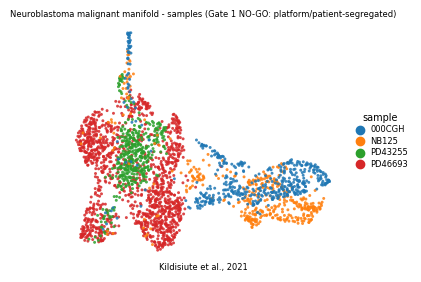

In [15]:
# deliverable: samples.pdf -- the Gate-1 evidence, a single sample-coloured manifold UMAP (reference
# style). The two platform lobes and per-patient territories shown above ARE the NO-GO.
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, color='sample', size=18, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.3, fontsize=6, title='sample', title_fontsize=7)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Neuroblastoma malignant manifold - samples (Gate 1 NO-GO: platform/patient-segregated)', size=6.0)
ax.text(.5, -.06, 'Kildisiute et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])